# 01 · Data and labels

**Purpose.** Before modelling anything, pin down what the data actually says. This notebook answers four questions:

1. Is the snapshot complete and correctly parsed?
2. What is *one inspection*, and which inspections are **routine** (the visits the city schedules and could re-order)?
3. Which routine visits were really **complaint-driven** and must be set aside?
4. What exactly is a **hit**, the outcome we will rank by?

**Output.** Clean, PII-free tables in `data/processed/` that notebooks 02 and 03 build on.

**Risks checked here** (IDs from the risk register in `PLAN.md`): R1 truncated download · R2 time zones · R3 inspection key · R4 history rewritten later · R6 cycle rule · R7 complaint matching · R8 junk codes · R9 one business, many licenses · R10 base rate · R12 drift · R18 personal data · R20 memory.
Every check goes through one small `check()` helper. If a check fails, the notebook stops, and the full list is printed at the end.

## 0 · Setup

In [1]:
import hashlib
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.neighbors import BallTree

from inspections import config

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 150)
TZ = 'America/New_York'
EARTH_RADIUS_M = 6_371_000

print(f'python {sys.version.split()[0]} · pandas {pd.__version__} · numpy {np.__version__}')
manifest = json.loads((config.RAW / 'manifest.json').read_text())
for name, m in manifest.items():
    print(f"{name:16s} {m['file']:34s} {m['rows']:>9,} rows · sha256 {m['sha256'][:12]}… · downloaded {m['downloaded_utc']}")

python 3.14.10 · pandas 3.1.1 · numpy 2.5.4
inspections      food_inspections_20261110.csv        908,247 rows · sha256 5e12e254f88d… · downloaded 2026-11-11T00:50:23
311_food_rodent  311_food_rodent_20261110.csv          68,360 rows · sha256 39b138b69e48… · downloaded 2026-11-11T00:51:26+00:00
weather          weather_logan_20261110.csv            33,184 rows · sha256 16029e734173… · downloaded 2026-11-11T00:54:54+00:00
census_income    census_income_zcta_20261111.csv       33,772 rows · sha256 c8b45ba568dd… · downloaded 2026-11-12T01:52:54+00:00


In [2]:
from inspections.checks import CheckLog

CHECKS = CheckLog()      # check(risk, what, ok, detail): record a data check; stop the notebook if it fails
check = CHECKS.check

## 1 · Load the snapshot

Every column is read as text first, so nothing is silently coerced, and types are parsed on purpose below.
The personal-name columns are removed **in the same cell**, so they never appear in any output (R18):

- `namefirst` / `namelast` (contact person) are dropped.
- `legalowner` is replaced by a short hash. We still want to know whether two licenses share an owner, but not who the owner is.

In [3]:
m = manifest['inspections']
raw = pd.read_csv(config.RAW / m['file'], dtype=str, keep_default_na=False, na_values=[''])

owner = raw['legalowner'].str.strip().str.upper()
raw['owner_id'] = owner.map(lambda s: hashlib.sha256(s.encode()).hexdigest()[:12], na_action='ignore')
raw = raw.drop(columns=['namefirst', 'namelast', 'legalowner'])

check('R1', 'pandas parsed every row the csv module counted', len(raw) == m['rows'], f'{len(raw):,} rows')
check('R1', 'download matches the portal row count at download time', m['rows'] == m['api_total'], f"api_total {m['api_total']:,}")
check('R18', 'personal-name columns are gone', not {'namefirst', 'namelast', 'legalowner'} & set(raw.columns))
check('R20', 'raw table fits comfortably in memory', raw.memory_usage(deep=True).sum() < 2e9,
      f'{raw.memory_usage(deep=True).sum() / 1e6:,.0f} MB')
raw.head(3)

✓ R1: pandas parsed every row the csv module counted  [908,247 rows]
✓ R1: download matches the portal row count at download time  [api_total 908,247]
✓ R18: personal-name columns are gone
✓ R20: raw table fits comfortably in memory  [516 MB]


,businessname,dbaname,licenseno,issdttm,expdttm,licstatus,licensecat,descript,result,resultdttm,violation,viol_level,violdesc,violdttm,viol_status,status_date,comments,address,city,state,zip,property_id,location,owner_id
0,1000 Degrees Pizza,NaN,313440,2017-08-14 12:49:37+00,2020-01-01 04:59:00+00,Inactive,FS,Eating & Drinking,HE_Fail,2018-03-20 14:54:25+00,13-2-304/402.11,*,Clean Cloths Hair Restraint,2018-03-20 14:54:25+00,Fail,NaN,One staff person without hair restraint. Provide,55 COURT ST,BOSTON,MA,02108,156226,"(42.35925954972639, -71.05890048027378)",29ad1382fc77
1,1000 Degrees Pizza,NaN,313440,2017-08-14 12:49:37+00,2020-01-01 04:59:00+00,Inactive,FS,Eating & Drinking,HE_Fail,2018-03-20 14:54:25+00,22-4-601/602.11,**,Food Contact Surfaces Clean,2018-03-20 14:54:25+00,Fail,NaN,Caked on food debris on can opener blade. Clea...,55 COURT ST,BOSTON,MA,02108,156226,"(42.35925954972639, -71.05890048027378)",29ad1382fc77
2,1000 Degrees Pizza,NaN,313440,2017-08-14 12:49:37+00,2020-01-01 04:59:00+00,Inactive,FS,Eating & Drinking,HE_Fail,2018-03-20 14:54:25+00,M-2-103.11,***,PIC Performing Duties,2018-03-20 14:54:25+00,Fail,NaN,Menu was redesigned allergy statement was remo...,55 COURT ST,BOSTON,MA,02108,156226,"(42.35925954972639, -71.05890048027378)",29ad1382fc77


## 2 · Timestamps → Boston local time (R2)

All timestamps are stored in UTC (`+00`). An inspection at 8 pm Boston time is already "tomorrow" in UTC, which would put it on the wrong day, and on the last day of a month, in the wrong month. Every date is converted to `America/New_York` before we derive days or months.

In [4]:
def to_local(col):
    return pd.to_datetime(raw[col], utc=True, format='mixed', errors='coerce').dt.tz_convert(TZ)

raw['visit_ts'] = to_local('resultdttm')
raw['viol_ts'] = to_local('violdttm')
raw['status_ts'] = to_local('status_date')
raw['issue_ts'] = to_local('issdttm')

utc_date = pd.to_datetime(raw['resultdttm'], utc=True, format='mixed', errors='coerce').dt.date
shifted = (utc_date != raw['visit_ts'].dt.date) & raw['visit_ts'].notna()
check('R2', 'visit timestamps are tz-aware Boston time', str(raw['visit_ts'].dt.tz) == TZ)
print(f'{shifted.mean():.1%} of rows fall on a different calendar date in UTC than in Boston')
print(f"{raw['visit_ts'].isna().mean():.2%} of rows have no visit timestamp; their results:",
      raw.loc[raw['visit_ts'].isna(), 'result'].value_counts().to_dict())

✓ R2: visit timestamps are tz-aware Boston time
0.5% of rows fall on a different calendar date in UTC than in Boston
0.70% of rows have no visit timestamp; their results: {'HE_Fail': 1942, 'HE_NotReq': 1670, 'HE_Pass': 1040, 'Pass': 514, 'HE_OutBus': 493, 'HE_Filed': 431, 'HE_FailExt': 105, 'HE_Hearing': 104, 'Fail': 83, 'HE_Closure': 7, 'HE_FAILNOR': 4, 'PassViol': 2, 'HE_TSOP': 2, 'HE_Misc': 1}


Rows without a visit timestamp (0.7%) can't be placed in a visit sequence, so they are dropped. They are a mix of codes, mostly older records, and too few to matter.

In [5]:
raw = raw[raw['visit_ts'].notna()].copy()
print(f'{len(raw):,} rows · {raw.visit_ts.min():%Y-%m-%d} → {raw.visit_ts.max():%Y-%m-%d}')

901,849 rows · 2006-04-04 → 2026-11-06


## 3 · Scope: which license types (R9)

The scope decision from the plan was FS / FT / RF in, mobile food (MFW) out. Here is the row and license volume behind it.

In [6]:
by_cat = raw.groupby(['licensecat', 'descript']).agg(rows=('result', 'size'), licenses=('licenseno', 'nunique'),
                                                     first=('visit_ts', 'min'), last=('visit_ts', 'max'))
by_cat[['first', 'last']] = by_cat[['first', 'last']].apply(lambda s: s.dt.strftime('%Y-%m'))
by_cat

,,rows,licenses,first,last
licensecat,descript,,,,
FS,Eating & Drinking,442922,4105,2006-04,2026-11
FT,Eating & Drinking w/ Take Out,342094,4041,2006-08,2026-11
MFW,Mobile Food Walk On,8499,423,2007-03,2026-11
RF,Retail Food,108334,2761,2006-11,2026-11


In [7]:
SCOPE = ['FS', 'FT', 'RF']
raw = raw[raw['licensecat'].isin(SCOPE)].copy()
print(f'{len(raw):,} rows in scope · {raw.licenseno.nunique():,} licenses')

893,350 rows in scope · 10,907 licenses


**One business, many licenses (R9).** When ownership changes, Boston issues a new license number, so a restaurant's history can be split across licenses at the same address. The opposite also happens: one site can hold two licenses at once (e.g. a restaurant plus a retail counter).

In [8]:
first_val = lambda s: s.dropna().iloc[0] if s.notna().any() else np.nan
lic = raw.groupby('licenseno').agg(category=('licensecat', 'first'), property_id=('property_id', first_val),
                                   owner_id=('owner_id', first_val), location=('location', first_val),
                                   zip=('zip', first_val), issue_ts=('issue_ts', 'min'),
                                   first_visit=('visit_ts', 'min'), last_visit=('visit_ts', 'max'))
per_pid = lic.dropna(subset=['property_id']).groupby('property_id').size()
print(f'licenses without a property_id: {lic.property_id.isna().mean():.1%}')
print(f'licenses that share their property_id with another license: '
      f'{lic.property_id.map(per_pid).gt(1).mean():.1%}')

# do licenses at the same property overlap in time (simultaneous) or follow each other (ownership change)?
shared = lic[lic.property_id.map(per_pid).gt(1)].sort_values(['property_id', 'first_visit'])
prev_last = shared.groupby('property_id').last_visit.shift()
overlap = (shared.first_visit < prev_last).dropna()
print(f'consecutive licenses at a shared property that overlap in time: {overlap.mean():.1%}  (the rest are successions)')

licenses without a property_id: 16.8%
licenses that share their property_id with another license: 58.5%
consecutive licenses at a shared property that overlap in time: 54.3%  (the rest are successions)


**Takeaway.** Over half of licenses share a `property_id`, and about half of those overlap in time. So `property_id` identifies a **building or parcel** (a mall, a food hall, a mixed-use block), not one business. It is too coarse to carry history from one license to the next. Each license is treated as its own establishment. Linking a new license to its predecessor at the same address goes to the backlog.

**Business age.** `issdttm` should be the license's original issue date. If it were a renewal date, it would usually fall *after* the license's first inspection.

In [9]:
issue_minus_first = (lic.issue_ts - lic.first_visit).dt.days
print('issue date − first inspection (days), quantiles:',
      issue_minus_first.quantile([.05, .25, .5, .75, .95]).round().to_dict())
print(f'licenses issued more than 30 days after their first inspection: {(issue_minus_first > 30).mean():.1%}')

issue date − first inspection (days), quantiles: {0.05: -3.0, 0.25: 2.0, 0.5: 39.0, 0.75: 1156.0, 0.95: 1676.0}
licenses issued more than 30 days after their first inspection: 50.8%


**It isn't usable.** About half of licenses have an issue date more than a month *after* their first inspection, so `issdttm` is often a re-issue or renewal date. Using it as business age would be wrong, and for some visits it would even lie in the future. **Decision:** measure experience as *days since the license's first recorded visit*, computed as of each visit. This is left-censored for licenses that already existed in 2006, which the model sees as "long history".

> **Not saved, on purpose (R5):** `licstatus`, `expdttm` and the current business name describe the license *as of today*. "Inactive" means the place closed at some point, possibly after the visit we are predicting. They are left out of every processed table.

## 4 · What is one inspection? (R3, R4)

The file has **one row per violation**. We need one row per visit.

In [10]:
key = ['licenseno', 'resultdttm']
results_per_key = raw.groupby(key)['result'].nunique()
per_day = raw.groupby(['licenseno', raw.visit_ts.dt.date]).agg(stamps=('resultdttm', 'nunique'))
print(f'distinct (license, timestamp) visits: {len(results_per_key):,}')
print(f'visits with more than one result code: {(results_per_key > 1).sum()}')
print(f'license-days with more than one visit timestamp: {(per_day.stamps > 1).mean():.2%}')
check('R3', '(license, timestamp) identifies a visit: <0.1% carry two result codes',
      (results_per_key > 1).mean() < 0.001, f'{(results_per_key > 1).sum()} visits')

distinct (license, timestamp) visits: 216,801
visits with more than one result code: 19
license-days with more than one visit timestamp: 0.80%
✓ R3: (license, timestamp) identifies a visit: <0.1% carry two result codes  [19 visits]


**Decision:** a visit = (`licenseno`, `resultdttm`). Two visits to one license on the same day (under 1% of license-days) stay separate, ordered by time.

**Is history rewritten later? (R4).** `viol_status` flips from *Fail* to *Pass* when a violation is cleared, and `status_date` records when. If old rows were updated in place, past visits would carry information from the future. We check how far `status_date` lies after the visit.

In [11]:
lag = (raw.status_ts - raw.visit_ts).dt.days
print(f'rows with a status_date: {raw.status_ts.notna().mean():.0%}')
print('status_date − visit (days), quantiles:', lag.quantile([.5, .75, .9, .95, .99]).to_dict())
print('rows whose status was set >1 day after the visit, by result:')
print(raw.loc[lag > 1, 'result'].value_counts().head(5).to_string())

rows with a status_date: 42%
status_date − visit (days), quantiles: {0.5: 0.0, 0.75: 0.0, 0.9: 2.0, 0.95: 3.0, 0.99: 10.0}
rows whose status was set >1 day after the visit, by result:
result
HE_Pass       37505
HE_Filed       7912
HE_FailExt     7464
HE_Hearing     1860
HE_Fail         916


**Takeaway.** Most status dates fall on the visit day. The exceptions sit mainly on *follow-up* visits (`HE_Pass` after a fail), where a cleared violation carries the date it was resolved. This confirms R4 is real but narrow.

**Rule for every later notebook:** features use only *which violations were cited at which visit, and when*. `viol_status` and `status_date` are never used as features.

Now we collapse to one row per visit, counting violations and severe (`***`) violations.

In [12]:
raw['is_severe'] = raw['viol_level'].eq('***')
raw['is_cited'] = raw['viol_status'].eq('Fail')

visits = (raw.groupby(key, as_index=False)
             .agg(visit_ts=('visit_ts', 'first'), result=('result', 'first'), category=('licensecat', 'first'),
                  n_viol=('violation', 'count'), n_severe=('is_severe', 'sum'), n_cited=('is_cited', 'sum'))
             .sort_values(['licenseno', 'visit_ts'], ignore_index=True))
print(f'{len(visits):,} visits')
visits.head()

216,801 visits


,licenseno,resultdttm,visit_ts,result,category,n_viol,n_severe,n_cited
0,105369,2022-09-14 17:47:39.71+00,2022-09-14 13:47:39.710-04:00,HE_NotReq,FS,0,0,0
1,105409,2013-08-26 15:22:35+00,2013-08-26 11:22:35.000-04:00,HE_Fail,FT,3,2,3
2,105409,2013-09-03 15:34:12+00,2013-09-03 11:34:12.000-04:00,HE_Pass,FT,3,2,0
3,105409,2013-12-30 05:00:00+00,2013-12-30 00:00:00.000-05:00,HE_NotReq,FT,0,0,0
4,105409,2014-03-04 19:28:29+00,2014-03-04 14:28:29.000-05:00,HE_Fail,FT,3,0,3


## 5 · What do the result codes mean? (R8)

The portal has no data dictionary for `result`, so we let the data tell us. For each code we look at:

- **with viol:** share of visits that list any violation
- **severe:** share with at least one `***` violation
- **cited:** share with at least one violation still marked *Fail*
- **after fail:** share where the *previous* visit was a fail (high means it's a follow-up)
- **days to next:** median days until the license's next visit (short means a re-inspection is coming)

In [13]:
FAIL_CODES = {'HE_Fail', 'HE_FailExt', 'HE_Hearing', 'HE_TSOP', 'HE_Closure', 'HE_FAILNOR', 'Fail', 'Failed'}
g = visits.groupby('licenseno')
visits['prev_result'] = g['result'].shift()
visits['days_to_next'] = (g['visit_ts'].shift(-1) - visits['visit_ts']).dt.days

codes = (visits.assign(with_viol=visits.n_viol > 0, severe=visits.n_severe > 0, cited=visits.n_cited > 0,
                       after_fail=visits.prev_result.isin(FAIL_CODES))
               .groupby('result')
               .agg(visits=('result', 'size'), with_viol=('with_viol', 'mean'), severe=('severe', 'mean'),
                    cited=('cited', 'mean'), after_fail=('after_fail', 'mean'), days_to_next=('days_to_next', 'median'))
               .sort_values('visits', ascending=False))
codes.style.format({'visits': '{:,}', 'with_viol': '{:.0%}', 'severe': '{:.0%}', 'cited': '{:.0%}',
                    'after_fail': '{:.0%}', 'days_to_next': '{:.0f}'})

,visits,with_viol,severe,cited,after_fail,days_to_next
result,,,,,,
HE_Pass,"89,333",61%,28%,0%,60%,172
HE_Fail,"64,219",100%,52%,99%,2%,7
HE_Filed,"25,239",99%,18%,99%,36%,176
HE_NotReq,"21,223",0%,0%,0%,4%,98
HE_FailExt,"10,566",100%,54%,98%,97%,10
HE_Hearing,"3,353",99%,66%,98%,96%,7
HE_OutBus,"1,051",17%,10%,11%,17%,597
HE_TSOP,763,84%,68%,83%,22%,3
HE_VolClos,550,99%,51%,99%,12%,1


**Reading the table:**

| Code | What the data says | Role we assign |
|---|---|---|
| `HE_Fail` | Violations cited; almost never right after another fail; next visit about a week later | **fail**, opens a cycle that needs follow-up |
| `HE_FailExt`, `HE_Hearing` | Nearly always right after a fail | **fail**, an escalated follow-up |
| `HE_TSOP`, `HE_Closure` | Permit suspended / closed | **fail** (severe) |
| `HE_Pass` | Often right after a fail, listing the earlier violations as cleared | **pass**, closes a cycle |
| `HE_Filed` | Violations cited, mostly minor; next visit months later (no follow-up needed) | **filed**: closes a cycle like a pass, and is *not* a fail |
| `HE_NotReq` | No violations at all; many share one batch timestamp | **admin**, dropped |
| `HE_OutBus`, `HE_VolClos` | Business closed | **closed**, dropped |
| legacy `Pass` / `Fail` / small codes | A handful of pre-2010 rows | mapped by name |

In [14]:
RESULT_ROLE = {
    **{c: 'fail' for c in FAIL_CODES},
    'HE_Pass': 'pass', 'Pass': 'pass', 'PassViol': 'pass', 'NoViol': 'pass',
    'HE_Filed': 'filed',
    'HE_NotReq': 'admin', 'HE_Misc': 'admin', 'HE_Hold': 'admin', 'DATAERR': 'admin',
    'HE_OutBus': 'closed', 'HE_VolClos': 'closed', 'Closed': 'closed',
}
unmapped = set(visits.result.dropna().unique()) - set(RESULT_ROLE)
check('R8', 'every result code is mapped to a role', not unmapped, f'unmapped: {sorted(unmapped)}' if unmapped else '')
visits['role'] = visits.result.map(RESULT_ROLE)
visits.role.value_counts()

✓ R8: every result code is mapped to a role


role
pass      89552
fail      79061
filed     25239
admin     21346
closed     1603
Name: count, dtype: int64

## 6 · Routine visits: the cycle rule (R6)

A routine inspection *opens a cycle*. If it fails, follow-up visits come until the place passes, and those follow-ups are mechanical consequences of the fail: the city doesn't choose when to make them. **Only cycle-opening visits are things the city could re-order**, so they are our prediction unit.

The data has no inspection-type field, so we infer it from the sequence of visits. First, how long after each kind of visit does the next one come?

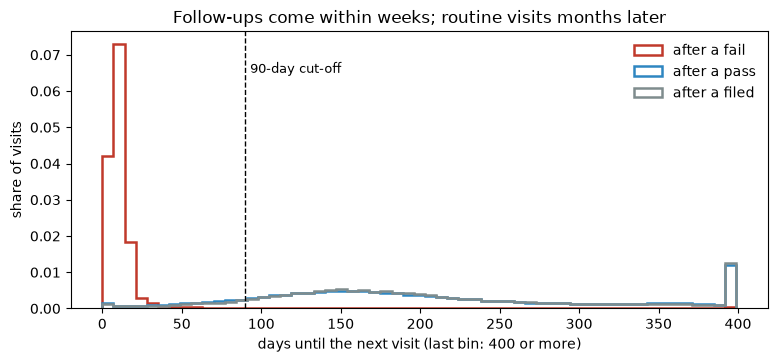

days to next visit after a FAIL, quantiles: {0.5: 7.0, 0.9: 16.0, 0.95: 27.0, 0.99: 174.0}


In [15]:
seq = visits[visits.role.isin(['fail', 'pass', 'filed'])].copy()
g = seq.groupby('licenseno')
seq['prev_role'] = g['role'].shift()
seq['gap_days'] = (seq['visit_ts'] - g['visit_ts'].shift()).dt.days

fig, ax = plt.subplots(figsize=(9, 3.6))
bins = np.arange(0, 400, 7)
for role, color in [('fail', '#c0392b'), ('pass', '#2e86c1'), ('filed', '#7f8c8d')]:
    ax.hist(seq.loc[seq.prev_role == role, 'gap_days'].clip(upper=399), bins=bins, histtype='step',
            lw=1.8, density=True, label=f'after a {role}', color=color)
ax.axvline(90, ls='--', c='k', lw=1)
ax.text(93, ax.get_ylim()[1] * .85, '90-day cut-off', fontsize=9)
ax.set(xlabel='days until the next visit (last bin: 400 or more)', ylabel='share of visits', title='Follow-ups come within weeks; routine visits months later')
ax.legend(frameon=False)
plt.show()
print('days to next visit after a FAIL, quantiles:', seq.loc[seq.prev_role == 'fail', 'gap_days'].quantile([.5, .9, .95, .99]).to_dict())

After a fail, 95% of next visits come within about four weeks. After a pass or filed visit, the typical gap is about six months. That supports the **chain rule** in the plan:

> A visit **opens a cycle** if it is the license's first visit, if the previous visit closed a cycle (pass or filed), or if it comes **≥ 90 days** after the previous visit (a follow-up that never happened, or a long closure). Everything else is a follow-up.

In [16]:
CYCLE_GAP = 90

def openers_for(gap):
    return seq.prev_role.isna() | seq.prev_role.isin(['pass', 'filed']) | (seq.gap_days >= gap)

seq['opener'] = openers_for(CYCLE_GAP)
seq['first_visit'] = seq.prev_role.isna()

print('result mix of cycle-OPENING visits:', seq[seq.opener].result.value_counts().head(5).to_dict())
print('result mix of FOLLOW-UP visits:   ', seq[~seq.opener].result.value_counts().head(5).to_dict())
share_fail_followups = seq.loc[seq.result == 'HE_Fail', 'opener'].mean()
share_ext_openers = seq.loc[seq.result.isin(['HE_FailExt', 'HE_Hearing']), 'opener'].mean()
check('R6', 'plain HE_Fail visits are almost always cycle openers (>95%)', share_fail_followups > .95, f'{share_fail_followups:.1%}')
check('R6', 'escalations (FailExt/Hearing) are almost never openers (<10%)', share_ext_openers < .10, f'{share_ext_openers:.1%}')

result mix of cycle-OPENING visits: {'HE_Fail': 63614, 'HE_Pass': 35658, 'HE_Filed': 16343, 'HE_TSOP': 602, 'HE_FailExt': 297}
result mix of FOLLOW-UP visits:    {'HE_Pass': 53675, 'HE_FailExt': 10269, 'HE_Filed': 8896, 'HE_Hearing': 3217, 'HE_Fail': 605}
✓ R6: plain HE_Fail visits are almost always cycle openers (>95%)  [99.1%]
✓ R6: escalations (FailExt/Hearing) are almost never openers (<10%)  [3.1%]


**Sensitivity of the cut-off.** If 60 or 120 days changed the prediction set much, our labels would depend on an arbitrary choice.

In [17]:
pd.DataFrame({gap: {'openers': int(openers_for(gap).sum()),
                    'change vs 90 days': f'{openers_for(gap).sum() / seq.opener.sum() - 1:+.1%}'}
              for gap in [30, 60, 90, 120, 180]}).T

,openers,change vs 90 days
30,118855,+1.6%
60,117409,+0.4%
90,116936,+0.0%
120,116646,-0.2%
180,116221,-0.6%


The prediction set barely moves between 60 and 120 days, so the rule is not fragile.

**Irregular openers.** A small share of openers come within 30 days of a *passing* visit. Routine schedules run every few months, so these are almost certainly not scheduled visits (complaint checks, license transfers, special events). They are flagged and set aside.

In [18]:
seq['irregular'] = seq.opener & ~seq.first_visit & (seq.gap_days < 30)
print(f"irregular openers: {seq.loc[seq.opener, 'irregular'].mean():.1%} of openers;",
      'results:', seq.loc[seq.irregular, 'result'].value_counts().head(3).to_dict())

irregular openers: 2.4% of openers; results: {'HE_Fail': 1269, 'HE_Pass': 1092, 'HE_Filed': 289}


## 7 · Complaint-driven visits (R7)

A visit triggered by a 311 complaint is not something a risk ranking can claim credit for, since the city already knew to go. We set those visits aside.

311 complaints carry coordinates, not a license number, so they must be matched by location. First, the obvious approach: *"any food complaint within r metres in the 30 days before the visit"*.

In [19]:
m311 = manifest['311_food_rodent']
c311 = pd.read_csv(config.RAW / m311['file'])
c311['open_ts'] = pd.to_datetime(c311['open_dt'], format='mixed').dt.tz_localize(TZ, ambiguous='NaT', nonexistent='NaT')
FOOD_COMPLAINTS = ['Unsanitary Conditions - Food', 'Unsanitary Conditions - Establishment',
                   'Unsanitary Conditions - Employees', 'Food Alert - Confirmed', 'Food Alert - Unconfirmed']
complaints = c311[c311['type'].isin(FOOD_COMPLAINTS) & c311.latitude.notna() & c311.open_ts.notna()].reset_index(drop=True)
print(f'{len(complaints):,} food complaints with coordinates · '
      f'{c311.latitude.isna().mean():.1%} of all 311 cases lack coordinates')

coords = lic['location'].str.extract(r'\(([-\d.]+),\s*([-\d.]+)\)').astype(float)
lic['lat'], lic['lon'] = coords[0], coords[1]
print(f'licenses without coordinates: {lic.lat.isna().mean():.1%}')

op = seq[seq.opener].join(lic[['lat', 'lon']], on='licenseno')
op = op[op.lat.notna()].reset_index(drop=True)

16,831 food complaints with coordinates · 1.5% of all 311 cases lack coordinates
licenses without coordinates: 9.9%


In [20]:
c_tree = BallTree(np.radians(complaints[['latitude', 'longitude']].to_numpy()), metric='haversine')
c_time = complaints.open_ts.to_numpy()

def naive_flag(radius_m, window_days=30):
    near = c_tree.query_radius(np.radians(op[['lat', 'lon']].to_numpy()), r=radius_m / EARTH_RADIUS_M)
    t = op.visit_ts.to_numpy()
    lo = (op.visit_ts - pd.Timedelta(days=window_days)).to_numpy()
    return np.array([len(i) > 0 and ((c_time[i] < t[k]) & (c_time[i] >= lo[k])).any() for k, i in enumerate(near)])

l_tree = BallTree(np.radians(lic[['lat', 'lon']].dropna().to_numpy()), metric='haversine')
op['licenses_within_50m'] = l_tree.query_radius(np.radians(op[['lat', 'lon']].to_numpy()), r=50 / EARTH_RADIUS_M, count_only=True)
dense = op.licenses_within_50m > 10
sparse = op.licenses_within_50m <= 1
naive = {}
for r in [25, 50, 100]:
    flag = naive_flag(r)
    naive[f'{r} m'] = {'openers flagged': flag.mean(), 'in dense blocks (>10 licenses within 50 m)': flag[dense].mean(),
                       'in sparse blocks (≤1 license within 50 m)': flag[sparse].mean()}
naive = pd.DataFrame(naive)
naive.style.format('{:.1%}')

,25 m,50 m,100 m
openers flagged,9.5%,12.4%,19.1%
in dense blocks (>10 licenses within 50 m),11.3%,16.1%,25.2%
in sparse blocks (≤1 license within 50 m),6.0%,6.5%,9.4%


**Problem.** A radius rule flags far too many visits: the median restaurant has about 9 licenses within 50 m (food halls, Downtown, Chinatown), and the flag rate climbs with density. One complaint lights up the whole block.

**Better rule: attribute each complaint to one establishment.** A complaint goes to the *nearest* establishment within 25 m that receives a cycle-opening visit 0–30 days after the complaint. Each complaint can then excuse at most one visit.

*Note:* this uses the visit date to decide which visit a complaint explains. That's fine for **labelling** visits as complaint-driven, but it is *not* a feature and is never shown to the model.

In [21]:
lic_xy = lic[['lat', 'lon']].dropna()
idx, dist = l_tree.query_radius(np.radians(complaints[['latitude', 'longitude']].to_numpy()),
                                r=25 / EARTH_RADIUS_M, return_distance=True)
pairs = pd.DataFrame({'complaint': np.repeat(np.arange(len(complaints)), [len(i) for i in idx]),
                      'licenseno': lic_xy.index.to_numpy()[np.concatenate(idx)],
                      'dist_m': np.concatenate(dist) * EARTH_RADIUS_M})
pairs['open_ts'] = complaints.open_ts.to_numpy()[pairs.complaint]
cand = pairs.merge(op[['licenseno', 'resultdttm', 'visit_ts']], on='licenseno')
cand['days_after'] = (cand.visit_ts - cand.open_ts).dt.total_seconds() / 86400
cand = cand[(cand.days_after >= 0) & (cand.days_after <= 30)]
best = cand.sort_values(['complaint', 'dist_m', 'days_after']).drop_duplicates('complaint')
complaint_visits = set(zip(best.licenseno, best.resultdttm))

seq['complaint_driven'] = [k in complaint_visits for k in zip(seq.licenseno, seq.resultdttm)]
share = seq.loc[seq.opener, 'complaint_driven'].mean()
print(f'complaints attributed to a visit: {len(best):,} of {len(complaints):,} ({len(best) / len(complaints):.0%})')
check('R7', 'attributed complaint visits are a plausible minority of openers (<10%)', share < .10, f'{share:.1%} of openers')

complaints attributed to a visit: 8,245 of 16,831 (49%)
✓ R7: attributed complaint visits are a plausible minority of openers (<10%)  [6.4% of openers]


About half of complaints lead to an attributable visit within 30 days. The rest are likely handled without a full inspection, were duplicates, or point at places without coordinates. The flagged share of openers is now plausible.

## 8 · What is a hit? (R10, R12)

Two candidate targets for a routine visit:

- **Fail:** the visit's result is a fail.
- **Severe:** at least one `***` violation is cited.

Base rates by year over routine openers (complaint-driven and irregular visits excluded):

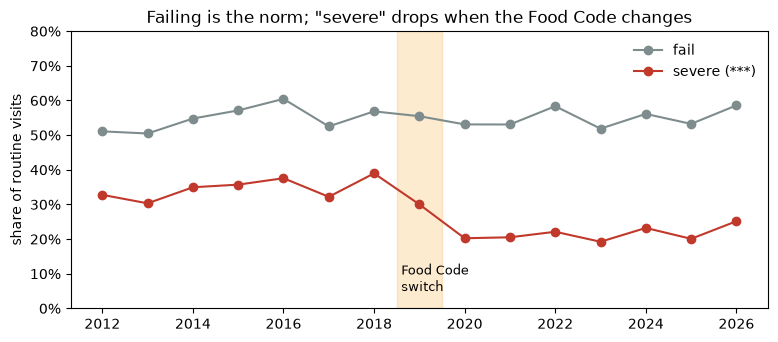

year,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
y_fail,51%,50%,55%,57%,60%,53%,57%,55%,53%,53%,58%,52%,56%,53%,59%
y_severe,33%,30%,35%,36%,38%,32%,39%,30%,20%,21%,22%,19%,23%,20%,25%


In [22]:
routine = seq[seq.opener & ~seq.irregular & ~seq.complaint_driven].copy()
routine['year'] = routine.visit_ts.dt.year
routine['y_fail'] = routine.role.eq('fail')
routine['y_severe'] = routine.n_severe.gt(0)

rates = routine[routine.year.between(2012, 2026)].groupby('year')[['y_fail', 'y_severe']].mean()
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(rates.index, rates.y_fail, marker='o', label='fail', color='#7f8c8d')
ax.plot(rates.index, rates.y_severe, marker='o', label='severe (***)', color='#c0392b')
ax.axvspan(2018.5, 2019.5, color='#f5b041', alpha=.25)
ax.text(2018.6, .05, 'Food Code\nswitch', fontsize=9)
ax.set(ylim=(0, .8), ylabel='share of routine visits', title='Failing is the norm; "severe" drops when the Food Code changes')
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.legend(frameon=False)
plt.show()
rates.T.style.format('{:.0%}')

Two things stand out:

1. **More than half of routine visits fail, every year.** A target that's true for most visits leaves little to rank.
2. **"Severe" falls from about 35% to about 22% exactly when Boston adopted the 2013 FDA Food Code (2019).** That looks like a change of definition, not of hygiene. We confirm it by tabulating severity against the Food Code tag at the end of each violation description, `(P)` priority, `(Pf)` priority foundation, `(C)` core:

In [23]:
v = raw[raw.violation.notna()].copy()
v['food_code_tag'] = v.violdesc.str.extract(r'\((Pf|P|C)\)\s*$')[0].fillna('none')
v['era'] = np.where(v.visit_ts.dt.year >= 2020, '2020+', np.where(v.visit_ts.dt.year <= 2018, '≤2018', '2019'))
pd.crosstab([v.era, v.viol_level], v.food_code_tag)

food_code_tag          C      P     Pf    none
era   viol_level                              
2019  *            12697      0      0   16611
      **               0      4   5557    1323
      ***              0   1991      0    4093
2020+ *           165278      0      0     581
      **               0     37  75845     199
      ***              0  29287      0      91
≤2018 *                4      0      0  390931
      **               0      0      0   32974
      ***              0      0      0   91240
      1919             0      0      0       1

**From 2020 on, `***` is exactly the Food Code's *Priority* category.** These are the violations that directly cause foodborne illness: holding temperatures, cross-contamination, handwashing, sanitizing, cooking. Before 2019, `***` followed an older list, and 2019 is a mix.

### Decision: the hit
> **Hit = at least one Priority violation (`***`) cited at a routine visit**, labelled from **2020 onwards**.

Why:
- It is the public-health outcome: what the priority list should surface first.
- At about 22% it is selective. A perfect ranking could double the hit rate in the first half of the queue, whereas with "fail" (about 57%) the headroom is smaller.
- It has a single, stable definition from 2020 on (R12).

Visits before 2020 remain in the data as **history** for features. They just aren't used as labels. Severe is also nearly a subset of fail:

In [24]:
recent = routine[routine.year >= 2020]
print(f'P(severe | fail) = {recent[recent.y_fail].y_severe.mean():.0%} · P(severe | not fail) = {recent[~recent.y_fail].y_severe.mean():.1%}')
by_year = recent.groupby('year').y_severe.mean()
check('R12', 'hit rate is stable within the 2020+ label window (yearly range < 8 points)',
      by_year.max() - by_year.min() < .08, f'{by_year.min():.0%}–{by_year.max():.0%}')

P(severe | fail) = 38% · P(severe | not fail) = 1.0%
✓ R12: hit rate is stable within the 2020+ label window (yearly range < 8 points)  [19%–25%]


## 9 · The prediction set

Routine, cycle-opening visits from 2020 onwards, split by time (`config.py`). The test period is **locked**: it is used once, at the very end of Phase 2.

In [25]:
def split_of(ts):
    d = ts.dt.tz_localize(None)
    return np.select([d < config.TRAIN_START, d <= f'{config.TRAIN_END} 23:59:59', d <= f'{config.VALID_END} 23:59:59',
                      d <= f'{config.TEST_END} 23:59:59'],
                     ['history', 'train', 'valid', 'test'], default='after')

seq['split'] = split_of(seq.visit_ts)
seq['in_prediction_set'] = seq.opener & ~seq.irregular & ~seq.complaint_driven & seq.split.isin(['train', 'valid', 'test'])
seq['hit'] = seq.n_severe.gt(0)
seq['month'] = seq.visit_ts.dt.tz_localize(None).dt.to_period('M')

ps = seq[seq.in_prediction_set]
summary = ps.pivot_table(index='split', columns='category', values='hit', aggfunc=['size', 'mean'])
summary = summary.reindex(['train', 'valid', 'test'])
summary.style.format('{:.0%}', subset='mean').format('{:,}', subset='size')

In [26]:
monthly = ps.groupby(['split', 'month']).size()
print('routine visits per month (median, min):',
      {s: (int(monthly[s].median()), int(monthly[s].min())) for s in ['train', 'valid', 'test']})
rf_month = ps[ps.category == 'RF'].groupby('month').size()
print(f'RF alone: median {rf_month.median():.0f} visits per month')
print(f"first-ever visits of a license: {ps.first_visit.mean():.1%} of the prediction set")

routine visits per month (median, min): {'train': (474, 2), 'valid': (472, 343), 'test': (499, 402)}
RF alone: median 68 visits per month
first-ever visits of a license: 6.2% of the prediction set


About 450–550 routine visits a month, enough for a stable monthly ranking. The exceptions are April–May 2020 (pandemic shutdown, 2–3 visits each), which barely affect training. Retail food alone has only about 60 a month, so RF results will be reported pooled, with a separate, wider-CI breakdown (R11).

## 10 · Save processed tables

| File | Contents | Used by |
|---|---|---|
| `visits.parquet` | every pass / filed / fail visit since 2006, with role, cycle flags, split, hit | history features (nb 03) |
| `violations.parquet` | one row per cited violation: code, description, level, **comment text** | violation-mix features (nb 03), text models (nb 04) |
| `licenses.parquet` | category, issue date, property id, hashed owner, coordinates, zip; **no** `licstatus` (R5) | features |
| `complaints.parquet` | 311 food complaints and rodent reports with coordinates | neighbourhood features |

In [27]:
config.PROCESSED.mkdir(parents=True, exist_ok=True)

visit_cols = ['licenseno', 'resultdttm', 'visit_ts', 'month', 'category', 'result', 'role', 'n_viol', 'n_severe',
              'n_cited', 'gap_days', 'opener', 'first_visit', 'irregular', 'complaint_driven', 'split',
              'in_prediction_set', 'hit']
seq[visit_cols].assign(month=lambda d: d.month.astype(str)).to_parquet(config.PROCESSED / 'visits.parquet', index=False)

viol_cols = ['licenseno', 'resultdttm', 'visit_ts', 'viol_ts', 'violation', 'violdesc', 'viol_level', 'comments']
raw.loc[raw.violation.notna(), viol_cols].to_parquet(config.PROCESSED / 'violations.parquet', index=False)

lic[['category', 'issue_ts', 'property_id', 'owner_id', 'zip', 'lat', 'lon']].to_parquet(config.PROCESSED / 'licenses.parquet')

c311.loc[c311.latitude.notna() & c311.open_ts.notna(), ['open_ts', 'type', 'latitude', 'longitude']] \
    .to_parquet(config.PROCESSED / 'complaints.parquet', index=False)

saved = {f.name: f'{f.stat().st_size / 1e6:.1f} MB' for f in sorted(config.PROCESSED.glob('*.parquet'))}
check('R5', 'no snapshot-only license fields in processed tables',
      not {'licstatus', 'expdttm', 'businessname'} & set(pd.read_parquet(config.PROCESSED / 'licenses.parquet').columns))
check('R18', 'no personal-name columns in processed tables',
      all(not {'namefirst', 'namelast', 'legalowner'} & set(pd.read_parquet(f).columns) for f in config.PROCESSED.glob('*.parquet')))
saved

✓ R5: no snapshot-only license fields in processed tables
✓ R18: no personal-name columns in processed tables


{'complaints.parquet': '1.4 MB',
 'licenses.parquet': '0.4 MB',
 'nb04_e3_scores_distilbert-distilbert-base-uncased_2_256_2_3e-05_32_5.parquet': '0.6 MB',
 'violations.parquet': '37.3 MB',
 'visits.parquet': '5.1 MB'}

## 11 · The same tables from the package

The rules derived above now live in `src/inspections/prepare.py`; `python -m inspections.prepare` runs them on a fresh snapshot. Built that way, every table must be identical to the ones this notebook saved.

In [28]:
from inspections import prepare

built = prepare.build_tables(config.RAW / m['file'], config.RAW / m311['file'])
same = {name: df.equals(pd.read_parquet(config.PROCESSED / f'{name}.parquet')) for name, df in built.items()}
check('R23', 'the package rebuilds every processed table exactly', all(same.values()),
      ', '.join(f'{name}: {"identical" if s else "DIFFERENT"}' for name, s in same.items()))

✓ R23: the package rebuilds every processed table exactly  [visits: identical, violations: identical, licenses: identical, complaints: identical]


## Checks run in this notebook

In [29]:
pd.DataFrame(CHECKS)

,risk,check,result,detail
0,R1,pandas parsed every row the csv module counted,pass,"908,247 rows"
1,R1,download matches the portal row count at downl...,pass,"api_total 908,247"
2,R18,personal-name columns are gone,pass,
3,R20,raw table fits comfortably in memory,pass,516 MB
4,R2,visit timestamps are tz-aware Boston time,pass,
5,R3,"(license, timestamp) identifies a visit: <0.1%...",pass,19 visits
6,R8,every result code is mapped to a role,pass,
7,R6,plain HE_Fail visits are almost always cycle o...,pass,99.1%
8,R6,escalations (FailExt/Hearing) are almost never...,pass,3.1%
9,R7,attributed complaint visits are a plausible mi...,pass,6.4% of openers


## Findings and decisions

**Findings**
1. The snapshot is complete (908,247 rows = portal count) and parses cleanly. Personal names are removed at load.
2. One visit = (`licenseno`, `resultdttm`). Result codes behave consistently. `HE_Filed` means *"violations recorded, no follow-up required"*: it closes a cycle like a pass and is not a fail. `HE_NotReq` is administrative.
3. **Routine visits can be inferred reliably.** Follow-ups arrive within weeks of a fail, routine visits months apart. The chain rule (90-day cut-off) is insensitive to the exact threshold.
4. `issdttm` is often a re-issue date, so it is not business age, and `property_id` is a building rather than a business.
5. **Naive distance matching of 311 complaints over-flags dense blocks.** Attributing each complaint to one visit fixes this.
6. **Failing is the norm (about 57%), and "severe" changed meaning with the 2019 Food Code switch.** From 2020, `***` = FDA *Priority* violation, a stable and health-relevant definition.
7. About 6,000–7,000 routine visits a year (about 500 a month). Retail food is a small slice (about 13% of the prediction set).

**Decisions** (also logged in `PLAN.md`)
- **Hit = ≥ 1 Priority (`***`) violation at a routine, cycle-opening visit**, labelled from 2020. Fail is kept as a secondary outcome.
- Prediction set = cycle openers, minus irregular (< 30 days after a pass) and complaint-driven visits.
- Splits: train 2020–2023 · validation 2024 · test 2025-01 → 2026-10 (locked).
- Never used as features: `viol_status`, `status_date`, `licstatus`, `expdttm`, business name, `issdttm` (unreliable).
- Experience = days since the license's first recorded visit.

**For your review**
- Are you comfortable with the switch from "fail" to "Priority violation found" as the headline hit?
- Irregular and complaint-driven visits are excluded rather than scored. Agree?